# TP 3 — Clustering hiérarchique

**Cours :** *Hierarchical Clustering* (slides 65–88) — dendrogrammes, agglomératif vs divisif, single-linkage (invariant, lien avec Kruskal), méta-algorithme AHC et choix de la distance entre clusters (single, complete, average, Ward), bijection dendrogrammes ↔ ultramétriques, théorème de stabilité, UPGMA.

**À la fin de ce notebook, vous saurez :**
1. coder le **single-linkage** comme l'algorithme de Kruskal avec un **union-find** ;
2. coder le **méta-algorithme agglomératif** pour les 4 distances (single, complete, average, Ward) et comprendre leurs comportements (effet de chaîne, équilibre, lien avec k-means) ;
3. calculer l'**ultramétrique cophénétique** (hauteur du plus petit ancêtre commun) et vérifier empiriquement le **théorème de stabilité** du single-linkage ;
4. coder **UPGMA** ;
5. construire une allocation de portefeuille **Hierarchical Risk Parity** (López de Prado, 2016) et la comparer aux allocations classiques.

**Convention de sortie.** Toutes nos fonctions renvoient une *matrice de liaison* au format SciPy : la ligne $t$ vaut `[a, b, hauteur, taille]` et décrit la fusion des clusters `a` et `b` en un nouveau cluster d'identifiant $n + t$ (les points ont les identifiants $0..n-1$). On peut ainsi tracer les dendrogrammes avec `scipy.cluster.hierarchy.dendrogram` et comparer nos résultats à SciPy.

> 📗 **Version corrigée.** Toutes les cellules s'exécutent de bout en bout.

In [1]:
import sys, pathlib, warnings
_here = pathlib.Path.cwd()
ROOT = _here.parent if _here.name in ("exercices", "corriges") else _here
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tp_utils import *          # style graphique, check(), check_close(), timer()...
import tp_data                  # données réelles (cache / téléchargement) ou simulées

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
rng = np.random.default_rng(42)
from scipy.cluster.hierarchy import linkage as sp_linkage, dendrogram, cophenet, fcluster
from scipy.spatial.distance import pdist, squareform
from scipy.sparse.csgraph import connected_components
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score

## Partie 1 — Single-linkage = Kruskal

$\delta_{SL}(C, C') = \min_{p\in C, p'\in C'} d(p, p')$. Le cours montre l'**invariant** : à l'échelle $s$, les clusters sont exactement les **composantes connexes du graphe de $s$-voisinage** (arêtes $\{p, p'\}$ telles que $d(p,p')\le s$). Il suffit donc de parcourir les arêtes par longueur croissante et de fusionner les composantes qu'elles relient : c'est l'algorithme de **Kruskal** (arbre couvrant minimal), en $O(n^2 \log n)$ avec une structure **union-find**.

### Exercice 1.1 — Union-find (forêt d'ensembles disjoints)
`find` avec **compression de chemin**, `union` par **taille** (la racine du plus gros arbre devient la racine commune). `union` renvoie la nouvelle racine.

In [2]:
class UnionFind:
    def __init__(self, n):
        self.parent = np.arange(n)
        self.size = np.ones(n, dtype=int)

    def find(self, i):
        root = i
        while self.parent[root] != root:
            root = self.parent[root]
        while self.parent[i] != root:          # compression de chemin
            self.parent[i], i = root, self.parent[i]
        return root

    def union(self, i, j):
        ri, rj = self.find(i), self.find(j)
        if ri == rj:
            return ri
        if self.size[ri] < self.size[rj]:
            ri, rj = rj, ri
        self.parent[rj] = ri
        self.size[ri] += self.size[rj]
        return ri

In [3]:
# Test
uf = UnionFind(6)
uf.union(0, 1); uf.union(2, 3); uf.union(1, 3)
check(uf.find(0) == uf.find(2) and uf.find(4) != uf.find(0), "union-find : composantes correctes")
check(uf.size[uf.find(0)] == 4, "union-find : taille de la composante")

✅ union-find : composantes correctes
✅ union-find : taille de la composante


### Exercice 1.2 — `single_linkage(D)`
Entrée : matrice de distances $D$ ($n\times n$). Parcourir les paires $i<j$ par distance croissante ; si $i$ et $j$ sont dans des composantes différentes, enregistrer la fusion. Il faut maintenir, pour chaque racine de l'union-find, l'**identifiant de cluster** courant (pour remplir la matrice de liaison).

In [4]:
def single_linkage(D):
    n = len(D)
    I, J = np.triu_indices(n, 1)
    w = D[I, J]
    order = np.argsort(w, kind="stable")
    uf = UnionFind(n)
    cid = np.arange(n)                  # cid[racine] = identifiant du cluster
    Z = []
    for e in order:
        ri, rj = uf.find(I[e]), uf.find(J[e])
        if ri == rj:
            continue
        a, b = cid[ri], cid[rj]
        r = uf.union(ri, rj)
        Z.append([min(a, b), max(a, b), w[e], uf.size[r]])
        cid[r] = n + len(Z) - 1
        if len(Z) == n - 1:
            break
    return np.array(Z, dtype=float)

Pour comparer deux hiérarchies sans dépendre de l'ordre des fusions à égalité, on compare leurs **ultramétriques cophénétiques** : $d_{LCA}(p_i,p_j)$ = hauteur du plus petit ancêtre commun (*least common ancestor*) de $p_i$ et $p_j$. Le cours montre que le dendrogramme est entièrement déterminé par $d_{LCA}$.

### Exercice 1.3 — `cophenetic(Z)`
Parcourir les fusions dans l'ordre en maintenant la liste des membres de chaque cluster ; à la fusion de $A$ et $B$ à la hauteur $h$, $d_{LCA}(a, b) = h$ pour tout $a\in A$, $b\in B$.

In [5]:
def cophenetic(Z):
    n = len(Z) + 1
    members = {i: [i] for i in range(n)}
    C = np.zeros((n, n))
    for t, (a, b, h, _) in enumerate(Z):
        A, B = members.pop(int(a)), members.pop(int(b))
        C[np.ix_(A, B)] = h
        C[np.ix_(B, A)] = h
        members[n + t] = A + B
    return C

In [6]:
# Tests
X = rng.normal(size=(150, 2))
D = squareform(pdist(X))
Z = single_linkage(D)
check(Z.shape == (149, 4), "n − 1 fusions")
check_close(Z[:, 2], sp_linkage(pdist(X), "single")[:, 2], "hauteurs = scipy (single)")
check_close(cophenetic(Z), squareform(cophenet(sp_linkage(pdist(X), "single"))), "cophénétique = scipy")

# Invariant du cours : clusters à l'échelle s = composantes connexes du graphe de s-voisinage
s = np.quantile(Z[:, 2], 0.8)
n_cc, cc = connected_components(D <= s, directed=False)
check(adjusted_rand_score(cc, fcluster(Z, s, "distance")) == 1.0,
      f"à l'échelle s = {s:.3f} : clusters = composantes connexes ({n_cc})")

✅ n − 1 fusions
✅ hauteurs = scipy (single)
✅ cophénétique = scipy
✅ à l'échelle s = 0.273 : clusters = composantes connexes (31)


## Partie 2 — Le méta-algorithme agglomératif (AHC)

```
chaque point est un cluster de hauteur 0
pour t = 1..n−1 : fusionner les deux clusters les plus proches pour δ ; hauteur = leur distance δ
```
Distances entre clusters vues en cours :
- **single** : $\min d(p,p')$ ;  **complete** : $\max d(p,p')$ ;  **average** : moyenne des $d(p,p')$ ;
- **Ward** : accroissement de la variance intra-cluster (pondérée) causé par la fusion,
$\delta_W(C, C') = |C\cup C'|\,\mathrm{Var}(C\cup C') - |C|\mathrm{Var}(C) - |C'|\mathrm{Var}(C') = \frac{|C||C'|}{|C|+|C'|}\|\bar C - \bar C'\|^2$ — même fonction objectif que k-means.

**Mise à jour efficace (formules de Lance-Williams).** Après fusion de $a$ et $b$ en $a\cup b$, la distance à tout autre cluster $k$ se calcule à partir des anciennes :
- single : $\min(\delta_{ak}, \delta_{bk})$ ; complete : $\max(\delta_{ak}, \delta_{bk})$ ;
- average : $\dfrac{n_a\delta_{ak} + n_b\delta_{bk}}{n_a + n_b}$ ;
- Ward (sur $\delta_W$, initialisée à $\tfrac12\|p_i - p_j\|^2$) : $\dfrac{(n_a+n_k)\delta_{ak} + (n_b+n_k)\delta_{bk} - n_k\delta_{ab}}{n_a+n_b+n_k}$.

On maintient une matrice $M$ des distances entre clusters actifs (diagonale $=+\infty$) : chaque étape coûte un `argmin` $O(n^2)$ et une mise à jour $O(n)$, soit $O(n^3)$ au total — très bien pour quelques centaines de points.

### Exercice 2.1 — `ahc(X, method)`

In [7]:
def ahc(X, method="average"):
    """AHC naïf en O(n^3). X : points (n x d). Retourne la matrice de liaison."""
    n = len(X)
    D = squareform(pdist(X))
    M = (0.5 * D ** 2 if method == "ward" else D.copy()).astype(float)
    np.fill_diagonal(M, np.inf)
    active = np.ones(n, bool)
    size = np.ones(n, dtype=int)
    cid = np.arange(n)                     # cid[ligne de M] = identifiant de cluster
    Z = []
    for t in range(n - 1):
        Mm = np.where(active[:, None] & active[None, :], M, np.inf)
        a, b = np.unravel_index(np.argmin(Mm), M.shape)
        h = M[a, b]
        na, nb, nk = size[a], size[b], size
        if method == "single":
            new = np.minimum(M[a], M[b])
        elif method == "complete":
            new = np.maximum(M[a], M[b])
        elif method == "average":
            new = (na * M[a] + nb * M[b]) / (na + nb)
        elif method == "ward":
            new = ((na + nk) * M[a] + (nb + nk) * M[b] - nk * h) / (na + nb + nk)
        else:
            raise ValueError(method)
        Z.append([min(cid[a], cid[b]), max(cid[a], cid[b]), h, na + nb])
        M[a, :] = new; M[:, a] = new; M[a, a] = np.inf
        active[b] = False; M[b, :] = np.inf; M[:, b] = np.inf
        size[a] = na + nb
        cid[a] = n + t
    return np.array(Z, dtype=float)

In [8]:
# Tests vs scipy (scipy exprime Ward comme sqrt(2 δ_W))
X = rng.normal(size=(120, 3))
for m in ["single", "complete", "average", "ward"]:
    Z = ahc(X, m)
    h = np.sqrt(2 * Z[:, 2]) if m == "ward" else Z[:, 2]
    check_close(np.sort(h), np.sort(sp_linkage(X, m)[:, 2]), f"hauteurs = scipy ({m})", rtol=1e-7)
    check(np.all(np.diff(Z[:, 2]) >= -1e-10), f"pas d'inversion de hauteurs ({m})")

✅ hauteurs = scipy (single)
✅ pas d'inversion de hauteurs (single)
✅ hauteurs = scipy (complete)
✅ pas d'inversion de hauteurs (complete)
✅ hauteurs = scipy (average)
✅ pas d'inversion de hauteurs (average)
✅ hauteurs = scipy (ward)
✅ pas d'inversion de hauteurs (ward)


### Expérience 2.2 — Impact du choix de $\delta$

Jeu de données : deux « lunes » imbriquées, un petit groupe compact, et quelques points bruités. On coupe chaque hiérarchie en 3 clusters.

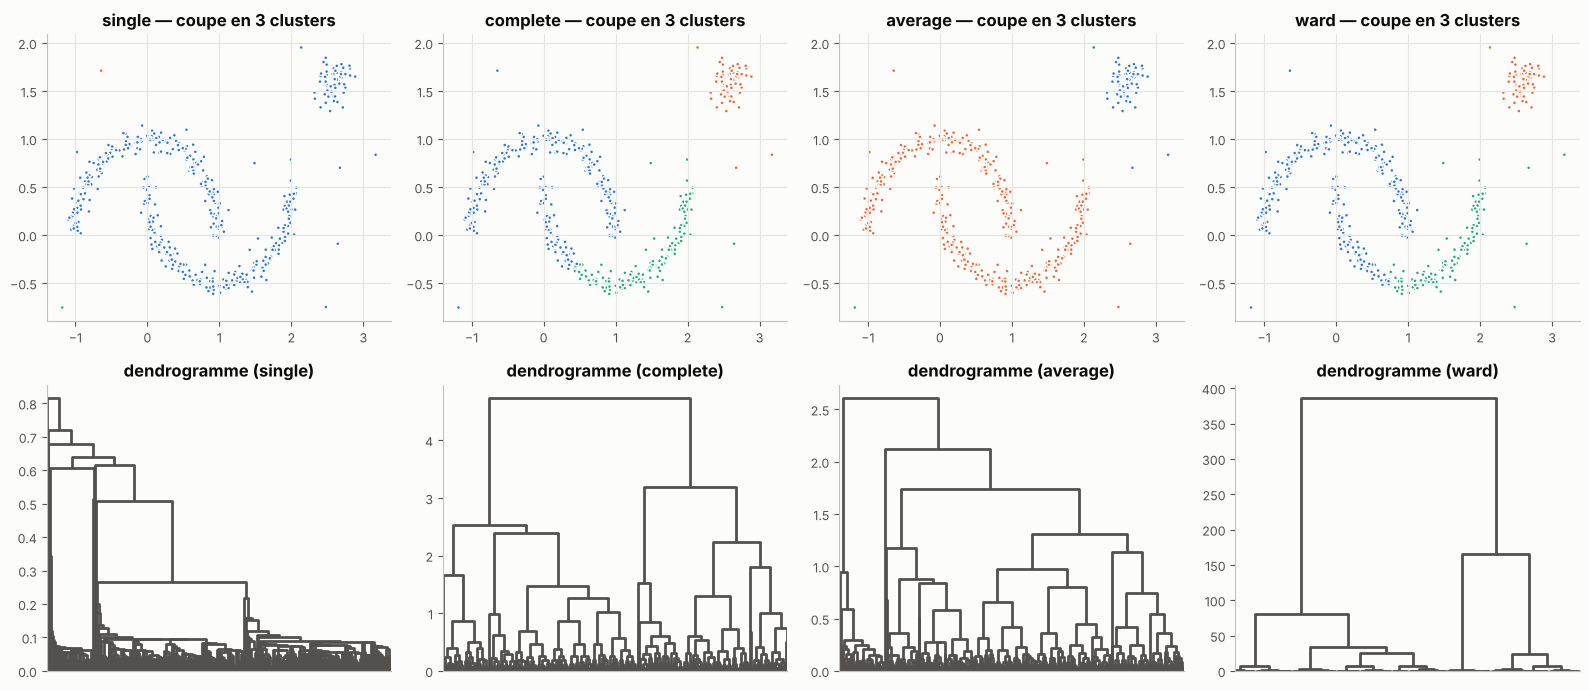

In [9]:
Xm, ym = make_moons(400, noise=0.06, random_state=0)
Xb = rng.normal([2.6, 1.6], 0.12, size=(60, 2))
Xn = rng.uniform([-1.2, -0.8], [3.2, 2.0], size=(15, 2))
Xs = np.vstack([Xm, Xb, Xn])

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for j, m in enumerate(["single", "complete", "average", "ward"]):
    Z = ahc(Xs, m)
    lab = fcluster(Z, 3, "maxclust")
    axes[0, j].scatter(*Xs.T, s=8, c=[PALETTE[(l - 1) % 8] for l in lab])
    axes[0, j].set_title(f"{m} — coupe en 3 clusters")
    dendrogram(Z, ax=axes[1, j], no_labels=True, color_threshold=0, above_threshold_color=INK2)
    axes[1, j].set_title(f"dendrogramme ({m})"); axes[1, j].grid(False)
plt.tight_layout(); plt.show()

**Question.** Décrivez le comportement de chaque distance sur cet exemple.

> **Corrigé.**
>
> - **Single** suit la géométrie (il « épouse » les lunes) mais est victime de l'**effet de chaîne** : quelques points bruités suffisent à relier des groupes, et la coupe en 3 isole souvent des points aberrants en clusters singletons. Dendrogramme très déséquilibré.
> - **Complete** produit des clusters compacts et un arbre **équilibré**, mais coupe les formes allongées (les lunes sont tranchées) et est sensible aux outliers (un point éloigné augmente le max).
> - **Average** est un compromis entre les deux.
> - **Ward** minimise l'accroissement de variance : il se comporte comme **k-means** (clusters globulaires de tailles comparables) — il ne récupère pas les lunes non plus.
> Aucune distance n'est « la bonne » : elle encode une hypothèse sur la forme des clusters.

## Partie 3 — Ultramétriques et stabilité

**Ultramétrique :** $d(x, z) \le \max\{d(x, y), d(y, z)\}$ pour tous $x, y, z$. Le cours montre que $\theta \mapsto d^\theta_{LCA}$ est une **bijection** entre dendrogrammes et ultramétriques (l'inverse étant le single-linkage).

**Théorème de stabilité** (Carlsson–Mémoli 2010) : pour deux métriques $d, d'$ sur $P$,
$$\max_{P\times P}\big|d_{LCA}^{SL(d)} - d_{LCA}^{SL(d')}\big| \le \max_{P\times P}|d - d'|.$$
Autrement dit, une petite perturbation des données ne change que peu les **hauteurs** des fusions du single-linkage (mais la **topologie** de l'arbre peut changer).

### Exercice 3.1 — Vérifier l'inégalité ultramétrique

In [10]:
def is_ultrametric(C, tol=1e-10):
    """Vrai si C vérifie C[x,z] <= max(C[x,y], C[y,z]) pour tous x, y, z."""
    rhs = np.maximum(C[:, :, None], C[None, :, :])        # rhs[x, y, z] = max(C[x,y], C[y,z])
    return bool(np.all(C[:, None, :] <= rhs + tol))

X = rng.normal(size=(60, 2)); D = squareform(pdist(X))
check(is_ultrametric(cophenetic(ahc(X, "average"))), "d_LCA (average) est une ultramétrique")
check(not is_ultrametric(D), "la distance euclidienne n'en est pas une")

✅ d_LCA (average) est une ultramétrique
✅ la distance euclidienne n'en est pas une


### Expérience 3.2 — Stabilité : single vs complete vs average

On perturbe un nuage de 80 points par un bruit uniforme de taille $\varepsilon$ et on calcule le rapport
$\rho = \max|d_{LCA} - d'_{LCA}| \,/\, \max|d - d'|$. Le théorème garantit $\rho \le 1$ pour le single-linkage.

In [11]:
ratios = {m: [] for m in ["single", "complete", "average"]}
for trial in range(200):
    X = rng.normal(size=(80, 2))
    Xp = X + rng.uniform(-0.05, 0.05, X.shape)
    dd = np.abs(squareform(pdist(X)) - squareform(pdist(Xp))).max()
    for m in ratios:
        c1, c2 = cophenetic(ahc(X, m)), cophenetic(ahc(Xp, m))
        ratios[m].append(np.abs(c1 - c2).max() / dd)
res = pd.DataFrame({m: [np.max(v), np.mean(np.array(v) > 1 + 1e-9)] for m, v in ratios.items()},
                   index=["rapport max", "fraction des essais où ρ > 1"]).T
check(res.loc["single", "rapport max"] <= 1 + 1e-9, "théorème de stabilité vérifié pour le single-linkage")
res

✅ théorème de stabilité vérifié pour le single-linkage


,rapport max,fraction des essais où ρ > 1
single,1.0000,0.0
complete,54.9835,1.0
average,22.6206,1.0


### Expérience 3.3 — … mais l'effet de chaîne

La stabilité porte sur les perturbations **petites partout**. Quelques points ajoutés (outliers) peuvent au contraire tout changer : un « pont » de 8 points entre deux groupes fait chuter la hauteur de leur fusion en single-linkage.

In [12]:
A = rng.normal([0, 0], 0.3, (100, 2)); B = rng.normal([4, 0], 0.3, (100, 2))
bridge = np.c_[np.linspace(0.6, 3.4, 8), rng.normal(0, 0.05, 8)]
rows = []
for name, X in [("sans pont", np.vstack([A, B])), ("avec 8 points de pont", np.vstack([A, B, bridge]))]:
    rows.append([name] + [ahc(X, m)[-1, 2] for m in ["single", "complete", "average"]])
pd.DataFrame(rows, columns=["données", "hauteur racine single", "complete", "average"]).set_index("données")

,hauteur racine single,complete,average
données,,,
sans pont,2.3872,5.7325,4.0620
avec 8 points de pont,0.4394,5.7325,3.9549


## Partie 4 — UPGMA et arbres phylogénétiques

UPGMA (*unweighted pair group method with arithmetic mean*) construit un arbre « à horloge moléculaire » : on lance l'**average-linkage** sur la matrice de dissimilarités, puis on **divise les hauteurs par 2** (la distance entre deux espèces = 2 × le temps écoulé depuis leur ancêtre commun). Théorème : si $d$ est une ultramétrique, UPGMA la retrouve exactement : $d^{\theta'}_{LCA} = d/2$.

### Exercice 4.1 — `upgma(D)`
Notre `ahc` prend des points ; écrivez une variante sur matrice de distances (average-linkage uniquement), puis divisez les hauteurs par 2.

In [13]:
def average_linkage_from_D(D):
    n = len(D)
    M = D.astype(float).copy(); np.fill_diagonal(M, np.inf)
    active = np.ones(n, bool); size = np.ones(n, dtype=int); cid = np.arange(n); Z = []
    for t in range(n - 1):
        Mm = np.where(active[:, None] & active[None, :], M, np.inf)
        a, b = np.unravel_index(np.argmin(Mm), M.shape)
        h, na, nb = M[a, b], size[a], size[b]
        new = (na * M[a] + nb * M[b]) / (na + nb)
        Z.append([min(cid[a], cid[b]), max(cid[a], cid[b]), h, na + nb])
        M[a, :] = new; M[:, a] = new; M[a, a] = np.inf
        active[b] = False; M[b, :] = np.inf; M[:, b] = np.inf
        size[a] = na + nb; cid[a] = n + t
    return np.array(Z)


def upgma(D):
    Z = average_linkage_from_D(D)
    Z[:, 2] /= 2
    return Z

In [14]:
# Test : une ultramétrique (obtenue comme d_LCA d'une hiérarchie quelconque) est retrouvée exactement
U = cophenetic(ahc(rng.normal(size=(40, 2)), "complete"))
check(is_ultrametric(U), "U est une ultramétrique")
check_close(cophenetic(upgma(U)), U / 2, "UPGMA retrouve l'ultramétrique (à un facteur 1/2)")

✅ U est une ultramétrique
✅ UPGMA retrouve l'ultramétrique (à un facteur 1/2)


## Partie 5 — Application : structure hiérarchique du marché et *Hierarchical Risk Parity*

### 5.1 Dendrogramme des actions

Distance de corrélation (Mantegna, 1999) : $d_{ij} = \sqrt{(1-\rho_{ij})/2} \in [0, 1]$ — c'est une vraie métrique (à un facteur près, la distance euclidienne entre rendements standardisés). Le single-linkage sur cette distance est l'arbre couvrant minimal du marché (*MST*), un outil classique d'*econophysics*.

[tp_data] stocks_2015_2024 : yfinance indisponible (ModuleNotFoundError) — `pip install yfinance` pour les données réelles ; bascule sur la simulation
[tp_data] stocks_2015_2024 : données SIMULÉES (modèle à facteurs GARCH)
source : simulé | (2608, 64)


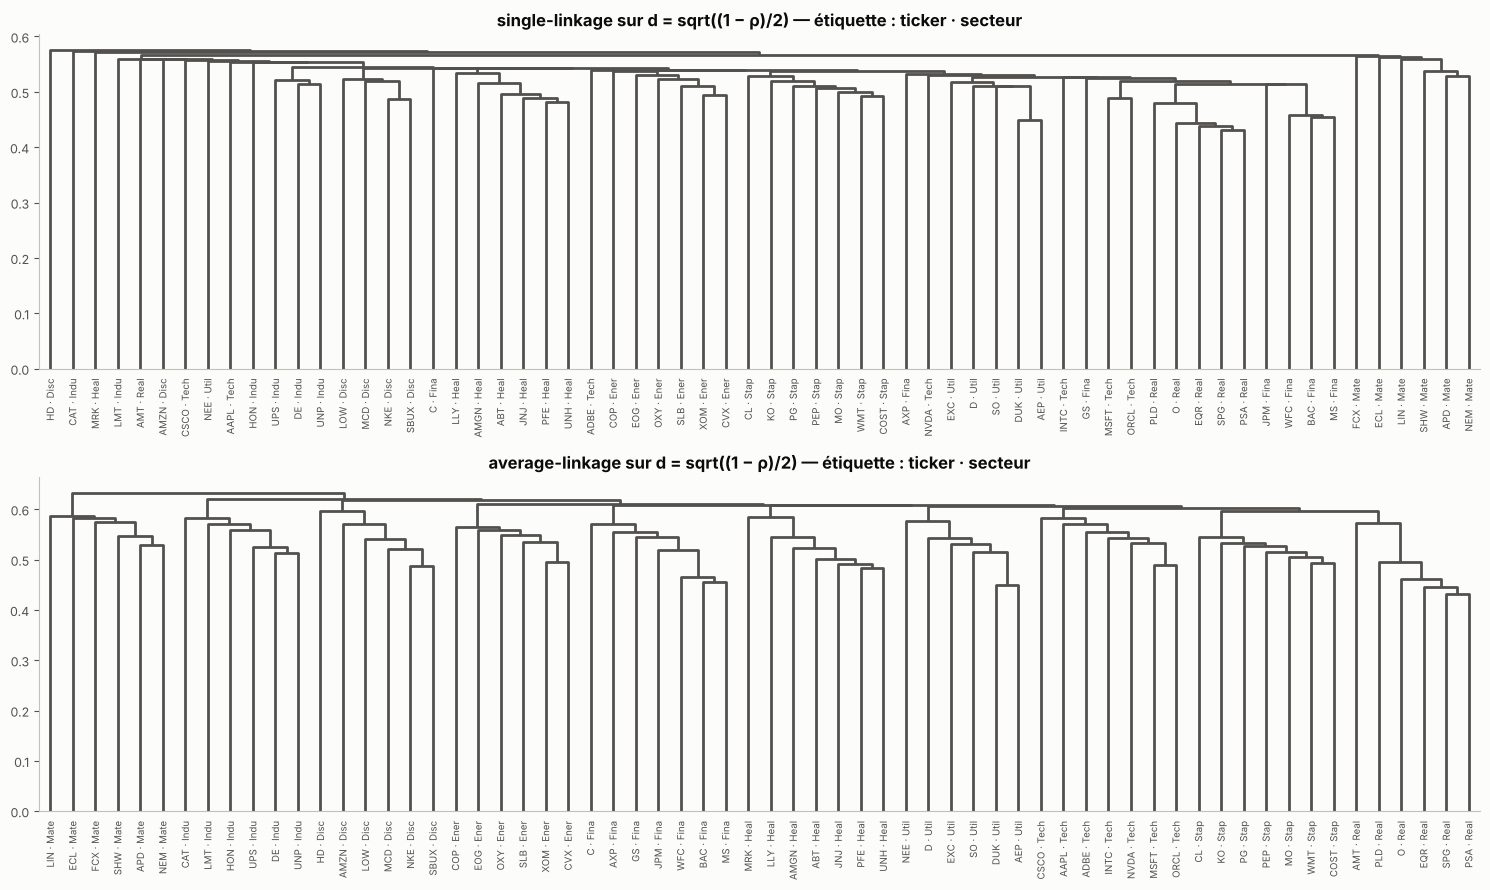

,ARI coupe à k = #secteurs,corrélation cophénétique
linkage,,
single,0.0270,0.671
average,0.8652,0.686


In [15]:
rets, sectors, src = tp_data.load_stock_returns()
print("source :", src, "|", rets.shape)
corr = rets.corr().to_numpy()
Dc = np.sqrt(np.clip((1 - corr) / 2, 0, None)); np.fill_diagonal(Dc, 0)
abbr = {s: s[:4] for s in sectors.unique()}
labels = [f"{t} · {abbr[sectors[t]]}" for t in rets.columns]

def linkage_from_D(D, method):
    if method == "single":
        return single_linkage(D)
    if method == "average":
        return average_linkage_from_D(D)
    raise ValueError(method)

rows = []
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
for ax, m in zip(axes, ["single", "average"]):
    Z = linkage_from_D(Dc, m)
    dendrogram(Z, ax=ax, labels=labels, leaf_font_size=7, color_threshold=0,
               above_threshold_color=INK2)
    ax.set_title(f"{m}-linkage sur d = sqrt((1 − ρ)/2) — étiquette : ticker · secteur"); ax.grid(False)
    cut = fcluster(Z, sectors.nunique(), "maxclust")
    rows.append((m, adjusted_rand_score(sectors, cut),
                 np.corrcoef(squareform(cophenetic(Z), checks=False), squareform(Dc, checks=False))[0, 1]))
plt.tight_layout(); plt.show()
pd.DataFrame(rows, columns=["linkage", "ARI coupe à k = #secteurs", "corrélation cophénétique"]).set_index("linkage")

La **corrélation cophénétique** (corrélation entre $d$ et $d_{LCA}$) mesure à quel point l'ultramétrique est fidèle aux distances d'origine ; l'ARI mesure l'accord d'une coupe avec les secteurs. Le single-linkage, fidèle aux hauteurs, produit des coupes déséquilibrées (effet de chaîne) ; l'average-linkage donne des coupes plus proches des secteurs.

### 5.2 Hierarchical Risk Parity (HRP)

Problème : l'allocation de **variance minimale** $w \propto \Sigma^{-1}\mathbf 1$ inverse une matrice de covariance estimée et bruitée → poids instables, concentrés, souvent décevants hors échantillon. HRP (López de Prado, 2016) évite l'inversion grâce à la hiérarchie :
1. **clustering hiérarchique** des actifs sur $d_{ij} = \sqrt{(1-\rho_{ij})/2}$ ;
2. **quasi-diagonalisation** : réordonner les actifs selon l'ordre des feuilles du dendrogramme (les actifs corrélés deviennent voisins) ;
3. **bissection récursive** : couper la liste ordonnée en deux moitiés $L_1, L_2$ ; leur variance $V_i = \tilde w_i^\top \Sigma_{L_i}\tilde w_i$ avec $\tilde w_i$ les poids inverse-variance *dans* $L_i$ ; allouer $\alpha = 1 - V_1/(V_1+V_2)$ à $L_1$ et $1-\alpha$ à $L_2$ ; recommencer dans chaque moitié.

### Exercice 5.1 — Ordre des feuilles et poids HRP

In [16]:
def leaf_order(Z):
    """Ordre gauche-droite des feuilles du dendrogramme (racine = dernier cluster)."""
    n = len(Z) + 1
    order, stack = [], [2 * n - 2]
    while stack:
        node = stack.pop()
        if node < n:
            order.append(node)
        else:
            a, b = Z[node - n, :2].astype(int)
            stack.extend([b, a])            # a sera dépilé en premier
    return order


def ivp_weights(cov):
    w = 1 / np.diag(cov)
    return w / w.sum()


def cluster_var(cov, idx):
    sub = cov[np.ix_(idx, idx)]
    w = ivp_weights(sub)
    return float(w @ sub @ w)


def hrp_weights(cov, order):
    """Poids HRP (tableau de taille n, dans l'ordre d'origine des actifs)."""
    w = np.ones(len(cov))
    clusters = [list(order)]
    while clusters:
        nxt = []
        for c in clusters:
            if len(c) <= 1:
                continue
            c1, c2 = c[: len(c) // 2], c[len(c) // 2:]
            v1, v2 = cluster_var(cov, c1), cluster_var(cov, c2)
            alpha = 1 - v1 / (v1 + v2)
            w[c1] *= alpha
            w[c2] *= 1 - alpha
            nxt += [c1, c2]
        clusters = nxt
    return w

In [17]:
# Tests
Z = single_linkage(Dc)
from scipy.cluster.hierarchy import leaves_list
check(leaf_order(Z) == list(leaves_list(Z)), "leaf_order = scipy.leaves_list")
cov = rets.cov().to_numpy()
w = hrp_weights(cov, leaf_order(Z))
check(np.isclose(w.sum(), 1) and np.all(w > 0), "poids HRP positifs, somme 1")
cov2 = np.diag([1.0, 4.0])
check_close(hrp_weights(cov2, [0, 1]), [0.8, 0.2], "2 actifs non corrélés : HRP = inverse-variance")

✅ leaf_order = scipy.leaves_list
✅ poids HRP positifs, somme 1
✅ 2 actifs non corrélés : HRP = inverse-variance


La quasi-diagonalisation en image : la matrice de corrélation dans l'ordre d'origine (alphabétique) puis dans l'ordre des feuilles.

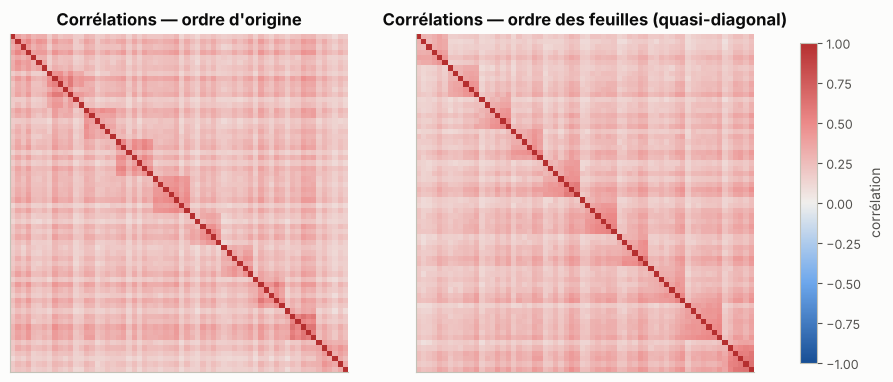

In [18]:
order = leaf_order(average_linkage_from_D(Dc))
fig, axes = plt.subplots(1, 2, figsize=(12, 5.2))
for ax, (title, o) in zip(axes, [("ordre d'origine", np.arange(len(corr))), ("ordre des feuilles (quasi-diagonal)", order)]):
    im = ax.imshow(corr[np.ix_(o, o)], cmap="div_blue_red", vmin=-1, vmax=1)
    ax.set_title(f"Corrélations — {title}"); ax.grid(False); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="corrélation")
plt.show()

### Exercice 5.2 — Backtest hors échantillon

Chaque mois (21 jours), on estime la covariance sur les 252 derniers jours, on calcule les poids, et on les applique aux 21 jours suivants. On compare :
- **1/N** (équipondéré), **inverse-variance** (IVP), **variance minimale** ($\Sigma^{-1}\mathbf 1$ normalisé, ventes à découvert permises),
- **HRP-single** et **HRP-average**.

Indicateurs : volatilité réalisée annualisée (l'objectif de ces allocations), *turnover* moyen par rebalancement $\sum_i |w_{i,t} - w_{i,t-1}|$, et concentration (nombre effectif d'actifs $1/\sum_i w_i^2$).

In [19]:
def weights_for(method, R_window):
    cov = R_window.cov().to_numpy()
    if method == "1/N":
        return np.full(cov.shape[0], 1 / cov.shape[0])
    if method == "IVP":
        return ivp_weights(cov)
    if method == "min-variance":
        w = np.linalg.solve(cov, np.ones(len(cov)))
        return w / w.sum()
    corr = R_window.corr().to_numpy()
    D = np.sqrt(np.clip((1 - corr) / 2, 0, None)); np.fill_diagonal(D, 0)
    Z = single_linkage(D) if method == "HRP-single" else average_linkage_from_D(D)
    return hrp_weights(cov, leaf_order(Z))

methods = ["1/N", "IVP", "min-variance", "HRP-single", "HRP-average"]
window, step = 252, 21
R = rets.to_numpy()
pnl = {m: [] for m in methods}; W_hist = {m: [] for m in methods}
with timer("backtest"):
    for t in range(window, len(R) - 1, step):
        Rw = rets.iloc[t - window:t]
        for m in methods:
            w = weights_for(m, Rw)
            W_hist[m].append(w)
            pnl[m].append(R[t:t + step] @ w)

summary = {}
for m in methods:
    p = np.concatenate(pnl[m]); W = np.array(W_hist[m])
    summary[m] = {"vol annualisée": p.std() * np.sqrt(252),
                  "turnover moyen": np.abs(np.diff(W, axis=0)).sum(1).mean(),
                  "nb effectif d'actifs": np.mean(1 / (W ** 2).sum(1)),
                  "poids max moyen": np.abs(W).max(1).mean()}
summary = pd.DataFrame(summary).T
observe(summary.loc["HRP-single", "turnover moyen"] < summary.loc["min-variance", "turnover moyen"],
      "HRP est beaucoup plus stable que la variance minimale")
summary

⏱  backtest : 1.135 s
✅ HRP est beaucoup plus stable que la variance minimale


,vol annualisée,turnover moyen,nb effectif d'actifs,poids max moyen
1/N,0.1523,0.0000,64.0000,0.0156
IVP,0.1505,0.0405,59.2296,0.0283
min-variance,0.1320,0.8657,5.3672,0.1543
HRP-single,0.1475,0.1396,56.9158,0.0318
HRP-average,0.1480,0.1383,57.4418,0.0322


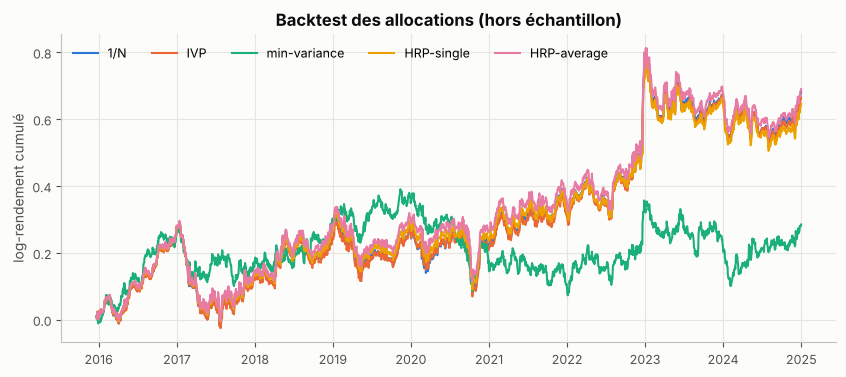

In [20]:
fig, ax = plt.subplots(figsize=(10, 4))
for i, m in enumerate(methods):
    p = np.concatenate(pnl[m])
    ax.plot(rets.index[window:window + len(p)], np.cumsum(np.log1p(p)), label=m, color=PALETTE[i], lw=1.5)
ax.set_ylabel("log-rendement cumulé"); ax.set_title("Backtest des allocations (hors échantillon)")
ax.legend(ncol=5, loc="upper left"); plt.show()

**Questions.**
1. Quelle méthode a la plus faible volatilité réalisée ? Est-ce suffisant pour la préférer ?
2. Pourquoi HRP est-il si peu sensible au bruit d'estimation ?
3. Single ou average pour HRP ?

> **Corrigé.**
>
> 1. La variance minimale vise exactement la volatilité minimale et l'atteint souvent hors échantillon *quand* la covariance est bien estimée (ici 252 observations pour ~60 actifs). Mais elle paie ce résultat par un **turnover** énorme et des poids extrêmes (positions courtes, concentration) : coûts de transaction, risque de modèle, capacité. Avec moins d'observations ou plus d'actifs ($T/N$ petit), $\hat\Sigma$ devient mal conditionnée et la variance minimale se dégrade fortement, alors que HRP reste robuste.
> 2. HRP n'inverse jamais $\hat\Sigma$ : il n'utilise que des variances de sous-portefeuilles (diagonale + blocs) et la structure hiérarchique, qui est stable (cf. théorème de stabilité sur les hauteurs). Les poids restent positifs, diversifiés, et varient peu d'un mois à l'autre.
> 3. López de Prado utilise le single-linkage ; l'ordre des feuilles qu'il produit est sensible à l'effet de chaîne. L'average-linkage donne une hiérarchie plus équilibrée, plus proche des secteurs. En pratique, la différence de risque est modeste ; on choisit souvent average ou Ward pour des arbres plus équilibrés.

## Partie 6 — Synthèse : quel algorithme, quand ?

**Agglomératif vs divisif.** À l'étape $k$, l'agglomératif choisit parmi $\binom{n-k}{2} = \Theta(n^2)$ fusions, le divisif parmi $\Theta(2^n)$ coupes : on utilise presque toujours l'**agglomératif**.

| Distance $\delta$ | Coût (impl. simple) | Propriétés | Quand l'utiliser |
|---|---|---|---|
| **Single** | $O(n^2\log n)$ (Kruskal) | invariant = composantes connexes ; **stable** (théorème) ; ultramétrique ↔ dendrogramme ; **effet de chaîne** | clusters de forme arbitraire bien séparés ; MST d'un réseau ; analyse topologique |
| **Complete** | $O(n^3)$ | arbre équilibré, clusters compacts ; sensible aux outliers ; pas de garantie | groupes compacts de diamètre contrôlé |
| **Average** | $O(n^3)$ | compromis équilibre / stabilité ; base d'UPGMA | choix par défaut raisonnable (corrélations, distances génériques) |
| **Ward** | $O(n^3)$ | même objectif que k-means ; clusters globulaires de tailles voisines ; données euclidiennes | quand on veut une hiérarchie « k-means » (et pour initialiser k-means) |
| **UPGMA** | $O(n^3)$ | average + hauteurs/2 ; exact si $d$ ultramétrique | arbres à « horloge moléculaire » (phylogénie), taxonomies |

**Hiérarchique vs k-means** : pas besoin de fixer $k$ (on coupe le dendrogramme après coup), vision multi-échelle, fonctionne avec une simple matrice de dissimilarités ; mais coût quadratique en mémoire et pas de remise en cause des fusions passées.